# Retail Demand Forecasting

This notebook develops and evaluates practical demand forecasting methods using historical retail sales data.

The analysis focuses on forecasting daily demand at the **Product × Store** level for the next **28 days**.

The analysis is designed to answer **Business Question 2:**

> How accurately can we forecast retail demand?

The forecasting results will later be used to identify where forecast errors are highest and what demand patterns are associated with those errors.

## 1. Forecasting Objective & Approach

The objective is to develop practical demand forecasts and evaluate their performance using historical demand patterns identified during the demand analysis.

The forecasting process will:

- Forecast demand at the **Product × Store** level.
- Forecast the next **28 days**.
- Compare practical forecasting methods.
- Evaluate forecasts using **WAPE, MAE, and Forecast Bias**.
- Compare forecast performance across products, categories, and stores.

The forecasting methods will include:

- Naive Forecast
- Moving Average
- Seasonal Naive Forecast

The analysis focuses on practical forecasting methods rather than machine learning models.

> **Forecasting principle:** The forecast will use only information available before the forecasting period. The actual demand for the 28-day evaluation period will be used only to evaluate forecast performance.

## 2. Load Prepared Data

In [90]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
sales_historical = pd.read_csv(
    "../data/processed/analytical/sales_historical.csv"
)

sales_evaluation = pd.read_csv(
    "../data/processed/analytical/sales_evaluation.csv"
)

calendar = pd.read_csv(
    "../data/processed/cleaned/calendar.csv",
    parse_dates=["date"]
)

- The forecasting analysis uses the prepared historical sales data, the 28-day evaluation-period sales data, and the calendar table for date mapping.
- Selling-price data is not required for the forecasting methods used in this analysis.

##### Verify Dataset Structure

In [6]:
sales_historical.shape, sales_evaluation.shape, calendar.shape

((58327370, 8), (853720, 8), (1969, 14))

In [7]:
sales_historical.head()

,id,item_id,dept_id,cat_id,store_id,state_id,d,demand
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0


In [8]:
sales_evaluation.head()

,id,item_id,dept_id,cat_id,store_id,state_id,d,demand
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1914,0
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,d_1914,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,d_1914,0
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,d_1914,0
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,d_1914,1


In [9]:
calendar.head()

,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1


##### Confirm Historical and Evaluation Periods

In [10]:
sales_historical["day_num"] = (
    sales_historical["d"].str.split("_").str[1].astype(int)
)

sales_evaluation["day_num"] = (
    sales_evaluation["d"].str.split("_").str[1].astype(int)
)

In [11]:
sales_historical["day_num"].min(), sales_historical["day_num"].max()

(np.int64(1), np.int64(1913))

In [12]:
sales_evaluation["day_num"].min(), sales_evaluation["day_num"].max()

(np.int64(1914), np.int64(1941))

In [13]:
sales_evaluation["day_num"].nunique()

28

##### Confirm the actual dates

In [14]:
calendar_dates = calendar.set_index("d")["date"]

historical_start = calendar_dates.loc["d_1"]
historical_end = calendar_dates.loc["d_1913"]

evaluation_start = calendar_dates.loc["d_1914"]
evaluation_end = calendar_dates.loc["d_1941"]

historical_start, historical_end, evaluation_start, evaluation_end

(Timestamp('2011-01-29 00:00:00'),
 Timestamp('2016-04-24 00:00:00'),
 Timestamp('2016-04-25 00:00:00'),
 Timestamp('2016-05-22 00:00:00'))

##### Forecasting Period

The historical dataset contains demand from **January 29, 2011 to April 24, 2016**.

The evaluation period covers the following **28 days**:

**April 25, 2016 to May 22, 2016**

Therefore, the forecasting scenario is:

> Use demand history through April 24, 2016 to forecast the following 28 days, then compare the forecasts with the actual demand observed during the evaluation period.

## 3. Forecasting Setup

### 3.1 Forecasting Grain

Demand will be forecast at the **Product × Store** level.

Each Product × Store combination represents an individual demand series, with daily demand observed over time.

**Example:**

`FOODS_3_090 × CA_3`

This allows the forecast to account for differences in demand between products and stores.

### 3.2 Forecast Horizon

The forecast horizon is **28 days**, corresponding to the evaluation period from **April 25, 2016 to May 22, 2016**.

The same 28-day horizon will be used for every Product × Store combination.

### 3.3 Forecasting Scenario

- The forecasting scenario simulates a real demand-planning situation.
- Only historical demand available up to **April 24, 2016** will be used to generate the forecast.
- The resulting forecasts will then be compared with the actual demand observed from **April 25 to May 22, 2016**.
- This ensures that the evaluation uses future observations that were not available when the forecasts were generated.

## 4. Prepare Forecasting Data

The prepared historical and evaluation datasets already contain demand at the **Product × Store × Day** level.

In this section, we will select the fields required for forecasting and evaluation while keeping the historical and actual evaluation data separate.


In [15]:
# Select Forecasting Columns

forecast_history = sales_historical[
    ["item_id", "store_id", "d", "day_num", "demand"]
].copy()

In [16]:
forecast_history.shape

(58327370, 5)

In [17]:
forecast_history.head()

,item_id,store_id,d,day_num,demand
0,HOBBIES_1_001,CA_1,d_1,1,0
1,HOBBIES_1_002,CA_1,d_1,1,0
2,HOBBIES_1_003,CA_1,d_1,1,0
3,HOBBIES_1_004,CA_1,d_1,1,0
4,HOBBIES_1_005,CA_1,d_1,1,0


In [18]:
# Prepare Actual Evaluation Data

forecast_actual = sales_evaluation[
    ["item_id", "store_id", "d", "day_num", "demand"]
].copy()

In [19]:
forecast_actual.shape

(853720, 5)

#### Validate Product × Store Coverage

In [20]:
historical_product_store = (
    forecast_history[
        ["item_id", "store_id"]
    ]
    .drop_duplicates()
)

evaluation_product_store = (
    forecast_actual[
        ["item_id", "store_id"]
    ]
    .drop_duplicates()
)

In [21]:
missing_product_store = evaluation_product_store.merge(
    historical_product_store,
    on=["item_id", "store_id"],
    how="left",
    indicator=True
)

missing_product_store[
    missing_product_store["_merge"] == "left_only"
]

,item_id,store_id,_merge


In [22]:
missing_product_store[
    missing_product_store["_merge"] == "left_only"
].shape

(0, 3)

##### Product × Store Coverage Validation

All **30,490 Product × Store combinations** in the 28-day evaluation period are also present in the historical data.

No Product × Store combinations are missing from the historical forecasting data, so the full evaluation period can be used for forecast generation and evaluation.

## 5. Naive Forecast

The Naive Forecast provides a simple baseline for comparison with the other forecasting methods.

For each Product × Store combination, the forecast for all 28 future days will use the **most recently observed demand** from the historical period.

For example, if the last observed demand for a Product × Store combination is 12 units:

- Day 1 forecast = 12
- Day 2 forecast = 12
- ...
- Day 28 forecast = 12

This method assumes that the most recent demand level continues throughout the forecast horizon.

The Naive Forecast will serve as the baseline against which the Moving Average and Seasonal Naive methods will be evaluated.

#### 5.1 Get the last observed demand

In [23]:
last_demand = (
    forecast_history
    .sort_values(["item_id", "store_id", "day_num"])
    .groupby(["item_id", "store_id"], as_index=False)
    .tail(1)
    [["item_id", "store_id", "demand"]]
    .rename(columns={"demand": "forecast_naive"})
)

last_demand.head()

,item_id,store_id,forecast_naive
58298492,FOODS_1_001,CA_1,0
58301541,FOODS_1_001,CA_2,4
58304590,FOODS_1_001,CA_3,0
58307639,FOODS_1_001,CA_4,1
58310688,FOODS_1_001,TX_1,0


In [24]:
last_demand.shape

(30490, 3)

#### 5.2 Create the 28-day Naive Forecast

In [25]:
forecast_dates = forecast_actual[
    ["d", "day_num"]
].drop_duplicates()

naive_forecast = (
    last_demand.assign(key=1)
    .merge(
        forecast_dates.assign(key=1),
        on="key"
    )
    .drop(columns="key")
)

naive_forecast.head()

,item_id,store_id,forecast_naive,d,day_num
0,FOODS_1_001,CA_1,0,d_1914,1914
1,FOODS_1_001,CA_1,0,d_1915,1915
2,FOODS_1_001,CA_1,0,d_1916,1916
3,FOODS_1_001,CA_1,0,d_1917,1917
4,FOODS_1_001,CA_1,0,d_1918,1918


#### 5.3 Validate the forecast

In [26]:
naive_forecast.shape

(853720, 5)

In [27]:
naive_forecast["forecast_naive"].isna().sum()

np.int64(0)

In [28]:
naive_forecast.head(10)

,item_id,store_id,forecast_naive,d,day_num
0,FOODS_1_001,CA_1,0,d_1914,1914
1,FOODS_1_001,CA_1,0,d_1915,1915
2,FOODS_1_001,CA_1,0,d_1916,1916
3,FOODS_1_001,CA_1,0,d_1917,1917
4,FOODS_1_001,CA_1,0,d_1918,1918
5,FOODS_1_001,CA_1,0,d_1919,1919
6,FOODS_1_001,CA_1,0,d_1920,1920
7,FOODS_1_001,CA_1,0,d_1921,1921
8,FOODS_1_001,CA_1,0,d_1922,1922
9,FOODS_1_001,CA_1,0,d_1923,1923


In [29]:
naive_forecast.tail(10)

,item_id,store_id,forecast_naive,d,day_num
853710,HOUSEHOLD_2_516,WI_3,0,d_1932,1932
853711,HOUSEHOLD_2_516,WI_3,0,d_1933,1933
853712,HOUSEHOLD_2_516,WI_3,0,d_1934,1934
853713,HOUSEHOLD_2_516,WI_3,0,d_1935,1935
853714,HOUSEHOLD_2_516,WI_3,0,d_1936,1936
853715,HOUSEHOLD_2_516,WI_3,0,d_1937,1937
853716,HOUSEHOLD_2_516,WI_3,0,d_1938,1938
853717,HOUSEHOLD_2_516,WI_3,0,d_1939,1939
853718,HOUSEHOLD_2_516,WI_3,0,d_1940,1940
853719,HOUSEHOLD_2_516,WI_3,0,d_1941,1941


In [30]:
naive_forecast.sample(10, random_state=42)

,item_id,store_id,forecast_naive,d,day_num
790812,HOUSEHOLD_2_292,CA_4,0,d_1922,1922
282451,FOODS_3_396,WI_1,1,d_1929,1929
163055,FOODS_2_368,CA_4,1,d_1925,1925
124237,FOODS_2_229,WI_1,0,d_1915,1915
484799,HOBBIES_1_303,TX_1,0,d_1921,1921
156971,FOODS_2_346,TX_3,8,d_1917,1917
825332,HOUSEHOLD_2_415,TX_3,0,d_1918,1918
54286,FOODS_1_197,WI_2,3,d_1936,1936
466973,HOBBIES_1_238,WI_1,0,d_1931,1931
646739,HOUSEHOLD_1_314,WI_1,0,d_1937,1937


##### Naive Forecast Validation

The Naive Forecast was generated for all **30,490 Product × Store combinations** across the 28-day evaluation horizon, resulting in **853,720 forecast observations**.

No missing forecast values were found. For each Product × Store combination, the most recently observed historical demand is carried forward unchanged across all 28 forecast days.

The Naive Forecast is therefore ready for evaluation against the actual demand.

## 6. Naive Forecast Evaluation

In [31]:
naive_evaluation = naive_forecast.merge(
    forecast_actual[
        ["item_id", "store_id", "d", "day_num", "demand"]
    ],
    on=["item_id", "store_id", "d", "day_num"],
    how="left"
).rename(columns={"demand": "actual_demand"})

naive_evaluation.head()

,item_id,store_id,forecast_naive,d,day_num,actual_demand
0,FOODS_1_001,CA_1,0,d_1914,1914,2
1,FOODS_1_001,CA_1,0,d_1915,1915,0
2,FOODS_1_001,CA_1,0,d_1916,1916,0
3,FOODS_1_001,CA_1,0,d_1917,1917,0
4,FOODS_1_001,CA_1,0,d_1918,1918,0


In [32]:
naive_evaluation.shape

(853720, 6)

In [33]:
naive_evaluation["actual_demand"].isna().sum()

np.int64(0)

### 6.1 WAPE, MAE, and Forecast Bias

In [34]:
total_actual = naive_evaluation["actual_demand"].sum()

wape = (
    (naive_evaluation["actual_demand"] - naive_evaluation["forecast_naive"])
    .abs()
    .sum()
    / total_actual
) * 100

mae = (
    naive_evaluation["actual_demand"] - naive_evaluation["forecast_naive"]
).abs().mean()

bias = (
    naive_evaluation["forecast_naive"]
    - naive_evaluation["actual_demand"]
).sum() / total_actual * 100

# wape, mae, bias

print(f"WAPE: {wape}")
print(f"MAE: {mae}")
print(f"BIAS: {bias}")

WAPE: 95.16206026479098
MAE: 1.3730169142107482
BIAS: 13.192137454902076


##### Naive Forecast — Performance

- The Naive Forecast achieved a **WAPE of 95.16%**, with an **MAE of 1.37 units** and a **positive forecast bias of 13.19%**.

- The high WAPE indicates that carrying the most recent demand forward does not capture the demand pattern effectively across the 28-day forecast horizon.

- The positive bias indicates that the Naive Forecast tended to over-forecast overall.

- The Naive Forecast will be used as the baseline for comparison with the Moving Average and Seasonal Naive methods.

## 7. Moving Average Forecast

The Moving Average Forecast uses the average demand from the most recent **7 historical days** for each Product × Store combination.

A 7-day window is used because the demand analysis identified a recurring **weekly demand pattern**. Using one complete week provides a simple way to smooth short-term fluctuations while representing the recent weekly demand level.

The calculated 7-day average is used as the forecast for each of the **28 future days**.

Only demand observed up to **April 24, 2016** is used to generate the forecast. The actual demand from the evaluation period is not used during forecasting.

#### 7.1 Calculate the 7-day historical average

In [35]:
moving_average = (
    forecast_history[
        forecast_history["day_num"].between(1907, 1913)
    ]
    .groupby(["item_id", "store_id"])["demand"]
    .mean()
    .reset_index()
    .rename(columns={"demand": "forecast_moving_average"})
)

moving_average.head()

,item_id,store_id,forecast_moving_average
0,FOODS_1_001,CA_1,1.142857
1,FOODS_1_001,CA_2,1.428571
2,FOODS_1_001,CA_3,0.142857
3,FOODS_1_001,CA_4,0.714286
4,FOODS_1_001,TX_1,0.000000


In [36]:
moving_average.shape

(30490, 3)

In [37]:
moving_average["forecast_moving_average"].isna().sum()

np.int64(0)

#### 7.2 Create the 28-day Moving Average forecast

In [38]:
moving_average_forecast = (
    moving_average.assign(key=1)
    .merge(
        forecast_dates.assign(key=1),
        on="key"
    )
    .drop(columns="key")
)

moving_average_forecast.head()

,item_id,store_id,forecast_moving_average,d,day_num
0,FOODS_1_001,CA_1,1.142857,d_1914,1914
1,FOODS_1_001,CA_1,1.142857,d_1915,1915
2,FOODS_1_001,CA_1,1.142857,d_1916,1916
3,FOODS_1_001,CA_1,1.142857,d_1917,1917
4,FOODS_1_001,CA_1,1.142857,d_1918,1918


In [39]:
moving_average_forecast.shape

(853720, 5)

In [40]:
moving_average_forecast["forecast_moving_average"].isna().sum()

np.int64(0)

#### 7.3 Evaluate the Moving Average

In [41]:
moving_average_evaluation = moving_average_forecast.merge(
    forecast_actual[
        ["item_id", "store_id", "d", "day_num", "demand"]
    ],
    on=["item_id", "store_id", "d", "day_num"],
    how="left"
).rename(columns={"demand": "actual_demand"})

moving_average_evaluation.head()

,item_id,store_id,forecast_moving_average,d,day_num,actual_demand
0,FOODS_1_001,CA_1,1.142857,d_1914,1914,2
1,FOODS_1_001,CA_1,1.142857,d_1915,1915,0
2,FOODS_1_001,CA_1,1.142857,d_1916,1916,0
3,FOODS_1_001,CA_1,1.142857,d_1917,1917,0
4,FOODS_1_001,CA_1,1.142857,d_1918,1918,0


In [42]:
moving_average_evaluation.shape

(853720, 6)

In [43]:
moving_average_evaluation["actual_demand"].isna().sum()

np.int64(0)

## 8. Moving Average Forecast Evaluation

In [44]:
total_actual = moving_average_evaluation["actual_demand"].sum()

wape_ma = (
    (moving_average_evaluation["actual_demand"] - moving_average_evaluation["forecast_moving_average"])
    .abs()
    .sum()
    / total_actual
) * 100

mae_ma = (
    moving_average_evaluation["actual_demand"]
    - moving_average_evaluation["forecast_moving_average"]
).abs().mean()

bias_ma = (
    moving_average_evaluation["forecast_moving_average"]
    - moving_average_evaluation["actual_demand"]
).sum() / total_actual * 100

# wape_ma, mae_ma, bias_ma

print(f"WAPE: {wape_ma}")
print(f"MAE: {mae_ma}")
print(f"BIAS: {bias_ma}")



WAPE: 74.04171114411064
MAE: 1.0682883648703825
BIAS: -7.359201925044083


##### Moving Average — Performance

- The 7-day Moving Average achieved a **WAPE of 74.04%**, an **MAE of 1.07 units**, and a **forecast bias of -7.36%**.
- Compared with the Naive Forecast, the Moving Average reduced both WAPE and MAE, indicating lower forecast error across the 28-day evaluation period.
- The forecast bias also changed from positive to negative. This indicates that the Moving Average tended to under-forecast overall, whereas the Naive Forecast tended to over-forecast.
- The Moving Average therefore provides a stronger baseline than the Naive method for this evaluation period, while its remaining bias should still be considered when comparing forecasting methods.

## 9. Seasonal Naive Forecast

The demand analysis identified a recurring **weekly demand pattern**, with demand levels differing systematically across days of the week.

Based on this finding, the Seasonal Naive method uses a **7-day seasonal cycle**. For each Product × Store combination, the demand from the final 7 historical days is used as the seasonal pattern and repeated across the 28-day forecast horizon.

For example:

- `d_1914` forecast uses demand from `d_1907`
- `d_1915` forecast uses demand from `d_1908`
- ...
- `d_1920` forecast uses demand from `d_1913`
- `d_1921` forecast again uses demand from `d_1907`

Only demand available through **April 24, 2016 (`d_1913`)** is used to generate the forecast.

This method tests whether incorporating a recurring weekly cycle improves forecast performance compared with the Naive and Moving Average methods.

#### 9.1 Extract the final historical week

In [45]:
seasonal_week = (
    forecast_history[
        forecast_history["day_num"].between(1907, 1913)
    ][
        ["item_id", "store_id", "day_num", "demand"]
    ]
    .copy()
)

seasonal_week.head()

,item_id,store_id,day_num,demand
58113940,HOBBIES_1_001,CA_1,1907,1
58113941,HOBBIES_1_002,CA_1,1907,0
58113942,HOBBIES_1_003,CA_1,1907,1
58113943,HOBBIES_1_004,CA_1,1907,4
58113944,HOBBIES_1_005,CA_1,1907,0


In [46]:
seasonal_week.shape

(213430, 4)

In [47]:
seasonal_week["demand"].isna().sum()

np.int64(0)

#### 9.2 Map the 7-day pattern to the 28 forecast days

In [48]:
seasonal_pattern = seasonal_week.copy()

# 1907 → 0
# 1908 → 1
# 1909 → 2
# 1910 → 3
# 1911 → 4
# 1912 → 5
# 1913 → 6

seasonal_pattern["seasonal_day"] = (
    seasonal_pattern["day_num"] - 1907
)

seasonal_pattern.head()

,item_id,store_id,day_num,demand,seasonal_day
58113940,HOBBIES_1_001,CA_1,1907,1,0
58113941,HOBBIES_1_002,CA_1,1907,0,0
58113942,HOBBIES_1_003,CA_1,1907,1,0
58113943,HOBBIES_1_004,CA_1,1907,4,0
58113944,HOBBIES_1_005,CA_1,1907,0,0


In [49]:
seasonal_pattern.tail()

,item_id,store_id,day_num,demand,seasonal_day
58327365,FOODS_3_823,WI_3,1913,1,6
58327366,FOODS_3_824,WI_3,1913,0,6
58327367,FOODS_3_825,WI_3,1913,0,6
58327368,FOODS_3_826,WI_3,1913,3,6
58327369,FOODS_3_827,WI_3,1913,0,6


#### 9.3 Create the 28-day seasonal positions

In [50]:
forecast_dates_seasonal = forecast_dates.copy()

forecast_dates_seasonal["seasonal_day"] = (
    (forecast_dates_seasonal["day_num"] - 1914) % 7
)

# Forecast day 1914 → historical position 0 → d_1907
# Forecast day 1915 → historical position 1 → d_1908
# ...
# Forecast day 1920 → historical position 6 → d_1913

# Forecast day 1921 → position 0 → d_1907 again

forecast_dates_seasonal

,d,day_num,seasonal_day
0,d_1914,1914,0
30490,d_1915,1915,1
60980,d_1916,1916,2
91470,d_1917,1917,3
121960,d_1918,1918,4
152450,d_1919,1919,5
182940,d_1920,1920,6
213430,d_1921,1921,0
243920,d_1922,1922,1
274410,d_1923,1923,2


#### 9.4 Create the Seasonal Naive Forecast

In [51]:
seasonal_naive_forecast = (
    forecast_dates_seasonal.assign(key=1)
    .merge(
        seasonal_pattern.assign(key=1),
        on=["key", "seasonal_day"],
        how="left"
    )
    .drop(columns=["key"])
)

seasonal_naive_forecast = seasonal_naive_forecast.rename(
    columns={"demand": "forecast_seasonal_naive"}
)

In [52]:
seasonal_naive_forecast.shape

(853720, 7)

In [53]:
seasonal_naive_forecast["forecast_seasonal_naive"].isna().sum()

np.int64(0)

In [54]:
seasonal_naive_forecast.columns

Index(['d', 'day_num_x', 'seasonal_day', 'item_id', 'store_id', 'day_num_y',
       'forecast_seasonal_naive'],
      dtype='str')

In [55]:
seasonal_naive_forecast = seasonal_naive_forecast[
    [
        "item_id",
        "store_id",
        "d",
        "day_num_x",
        "forecast_seasonal_naive"
    ]
].rename(columns={"day_num_x": "day_num"})

In [56]:
seasonal_naive_forecast.columns

Index(['item_id', 'store_id', 'd', 'day_num', 'forecast_seasonal_naive'], dtype='str')

#### 9.5 Evaluate it against actual demand

In [57]:
seasonal_naive_evaluation = seasonal_naive_forecast.merge(
    forecast_actual[
        ["item_id", "store_id", "d", "day_num", "demand"]
    ],
    on=["item_id", "store_id", "d", "day_num"],
    how="left"
).rename(columns={"demand": "actual_demand"})

In [58]:
seasonal_naive_evaluation.shape

(853720, 6)

In [59]:
seasonal_naive_evaluation["actual_demand"].isna().sum()

np.int64(0)

## 10. Seasonal Naive Forecast Evaluation 

In [60]:
total_actual = seasonal_naive_evaluation["actual_demand"].sum()

seasonal_wape = (
    (
        seasonal_naive_evaluation["actual_demand"]
        - seasonal_naive_evaluation["forecast_seasonal_naive"]
    )
    .abs()
    .sum()
    / total_actual
) * 100

seasonal_mae = (
    seasonal_naive_evaluation["actual_demand"]
    - seasonal_naive_evaluation["forecast_seasonal_naive"]
).abs().mean()

seasonal_bias = (
    seasonal_naive_evaluation["forecast_seasonal_naive"]
    - seasonal_naive_evaluation["actual_demand"]
).sum() / total_actual * 100

# seasonal_wape, seasonal_mae, seasonal_bias

print(f"WAPE: {seasonal_wape}")
print(f"MAE: {seasonal_mae}")
print(f"BIAS: {seasonal_bias}")


WAPE: 86.21813918900048
MAE: 1.2439722625685237
BIAS: -7.359201925044083


##### Seasonal Naive — Performance

- The Seasonal Naive Forecast achieved a **WAPE of 86.22%**, an **MAE of 1.24 units**, and a **forecast bias of -7.36%**.
- The negative bias indicates that the Seasonal Naive method tended to under-forecast overall.
- Compared with the Naive Forecast, the Seasonal Naive method produced lower MAE but higher WAPE. Its bias was also lower in magnitude than the Naive Forecast.
- The Seasonal Naive method therefore captures the recurring weekly pattern, but this does not necessarily translate into lower overall forecast error for this evaluation period.

### Forecasting Method Performance Summary

| Method | WAPE | MAE | Bias |
|---|---:|---:|---:|
| Naive Forecast | 95.16% | 1.37 | +13.19% |
| 7-Day Moving Average | 74.04% | 1.07 | -7.36% |
| Seasonal Naive | 86.22% | 1.24 | -7.36% |

The three forecasting methods are summarized using WAPE, MAE, and Forecast Bias for the 28-day evaluation period.

## 11. Forecast Method Comparison

In [61]:
comparison = pd.DataFrame({
    "Method": [
        "Naive Forecast",
        "7-Day Moving Average",
        "Seasonal Naive"
    ],
    "WAPE": [
        wape,
        74.04171114411064,
        seasonal_wape
    ],
    "MAE": [
        mae,
        1.0682883648703825,
        seasonal_mae
    ],
    "Bias": [
        bias,
        -7.359201925044083,
        seasonal_bias
    ]
})

comparison

,Method,WAPE,MAE,Bias
0,Naive Forecast,95.162060,1.373017,13.192137
1,7-Day Moving Average,74.041711,1.068288,-7.359202
2,Seasonal Naive,86.218139,1.243972,-7.359202


### Forecast Method Comparison — Key Observations

- The three methods show different forecast performance across the 28-day evaluation period.
- The 7-Day Moving Average produced the lowest WAPE and MAE among the three methods.
- The Seasonal Naive method produced lower error than the Naive Forecast but higher error than the 7-Day Moving Average.
- The Naive Forecast had positive bias, while both the Moving Average and Seasonal Naive methods had negative and equal bias.
- These results show that incorporating recent demand history through a 7-day average produced lower forecast error for this evaluation period than the other two methods.

## 12. Forecast Performance by Category

Overall forecast metrics show how the methods performed across the entire dataset. However, forecast performance may differ across product categories because demand patterns and volumes vary between categories.

This analysis compares forecast performance across **FOODS, HOBBIES, and HOUSEHOLD** using WAPE, MAE, and Forecast Bias.

The purpose is to identify whether forecast errors are concentrated in particular categories.

In [62]:
category_mapping = (
    sales_historical[
        ["item_id", "cat_id"]
    ]
    .drop_duplicates()
)

category_mapping.shape

(3049, 2)

In [63]:
naive_category = naive_evaluation.merge(
    category_mapping,
    on="item_id",
    how="left"
)

naive_category.shape

(853720, 7)

In [64]:
naive_category["cat_id"].isna().sum()

np.int64(0)

In [65]:
moving_average_category = moving_average_evaluation.merge(
    category_mapping,
    on="item_id",
    how="left"
)

seasonal_naive_category = seasonal_naive_evaluation.merge(
    category_mapping,
    on="item_id",
    how="left"
)

In [66]:
moving_average_category.shape, seasonal_naive_category.shape

((853720, 7), (853720, 7))

In [67]:
moving_average_category["cat_id"].isna().sum(), seasonal_naive_category["cat_id"].isna().sum()

(np.int64(0), np.int64(0))

In [68]:
# calculate category-level metrics for the Naive Forecast

naive_category_metrics = (
    naive_category
    .groupby("cat_id")
    .apply(
        lambda x: pd.Series({
            "WAPE": (
                (x["actual_demand"] - x["forecast_naive"]).abs().sum()
                / x["actual_demand"].sum()
            ) * 100,
            "MAE": (
                x["actual_demand"] - x["forecast_naive"]
            ).abs().mean(),
            "Bias": (
                (x["forecast_naive"] - x["actual_demand"]).sum()
                / x["actual_demand"].sum()
            ) * 100
        }),
        include_groups=False
    )
    .reset_index()
)

naive_category_metrics

,cat_id,WAPE,MAE,Bias
0,FOODS,86.776987,1.795427,9.828850
1,HOBBIES,127.922594,0.936827,13.178428
2,HOUSEHOLD,106.399690,1.028646,23.076706


In [69]:
# Calculate the same metrics for the 7-Day Moving Average

moving_average_category_metrics = (
    moving_average_category
    .groupby("cat_id")
    .apply(
        lambda x: pd.Series({
            "WAPE": (
                (x["actual_demand"] - x["forecast_moving_average"]).abs().sum()
                / x["actual_demand"].sum()
            ) * 100,
            "MAE": (
                x["actual_demand"] - x["forecast_moving_average"]
            ).abs().mean(),
            "Bias": (
                (x["forecast_moving_average"] - x["actual_demand"]).sum()
                / x["actual_demand"].sum()
            ) * 100
        }),
        include_groups=False
    )
    .reset_index()
)

moving_average_category_metrics

,cat_id,WAPE,MAE,Bias
0,FOODS,67.351876,1.393519,-9.027878
1,HOBBIES,102.954160,0.753973,-5.089076
2,HOUSEHOLD,81.872940,0.791528,-3.385788


In [70]:
# Calculate the Seasonal Naive category metrics

seasonal_naive_category_metrics = (
    seasonal_naive_category
    .groupby("cat_id")
    .apply(
        lambda x: pd.Series({
            "WAPE": (
                (x["actual_demand"] - x["forecast_seasonal_naive"]).abs().sum()
                / x["actual_demand"].sum()
            ) * 100,
            "MAE": (
                x["actual_demand"] - x["forecast_seasonal_naive"]
            ).abs().mean(),
            "Bias": (
                (x["forecast_seasonal_naive"] - x["actual_demand"]).sum()
                / x["actual_demand"].sum()
            ) * 100
        }),
        include_groups=False
    )
    .reset_index()
)

seasonal_naive_category_metrics

,cat_id,WAPE,MAE,Bias
0,FOODS,78.665638,1.627602,-9.027878
1,HOBBIES,118.645560,0.868887,-5.089076
2,HOUSEHOLD,95.146426,0.919853,-3.385788


In [71]:
category_comparison = pd.concat(
    [
        naive_category_metrics.assign(Method="Naive Forecast"),
        moving_average_category_metrics.assign(Method="7-Day Moving Average"),
        seasonal_naive_category_metrics.assign(Method="Seasonal Naive")
    ],
    ignore_index=True
)

category_comparison = category_comparison[
    ["cat_id", "Method", "WAPE", "MAE", "Bias"]
]

category_comparison

,cat_id,Method,WAPE,MAE,Bias
0,FOODS,Naive Forecast,86.776987,1.795427,9.828850
1,HOBBIES,Naive Forecast,127.922594,0.936827,13.178428
2,HOUSEHOLD,Naive Forecast,106.399690,1.028646,23.076706
3,FOODS,7-Day Moving Average,67.351876,1.393519,-9.027878
4,HOBBIES,7-Day Moving Average,102.954160,0.753973,-5.089076
5,HOUSEHOLD,7-Day Moving Average,81.872940,0.791528,-3.385788
6,FOODS,Seasonal Naive,78.665638,1.627602,-9.027878
7,HOBBIES,Seasonal Naive,118.645560,0.868887,-5.089076
8,HOUSEHOLD,Seasonal Naive,95.146426,0.919853,-3.385788


##### Category-Level Forecast Performance — Key Observations

- The **7-Day Moving Average** produced lower WAPE and MAE than the Naive and Seasonal Naive methods across all three categories during the evaluation period.
- **FOODS** had the lowest WAPE across the three categories for each forecasting method.
- **HOBBIES** had the highest WAPE across the three categories, despite having lower MAE than FOODS.
- The Naive Forecast showed positive bias across all categories, while the Moving Average and Seasonal Naive methods showed negative bias.
- Forecast performance therefore varies across categories, indicating that overall forecast metrics alone do not fully describe forecast reliability.

## 13. Forecast Performance by Store

Forecast performance can also vary across stores because demand levels and demand patterns differ by location.

This analysis compares the three forecasting methods across the **10 stores** using WAPE, MAE, and Forecast Bias.

The purpose is to identify whether forecast errors are concentrated in particular stores.

In [72]:
# calculating the Naive Forecast store-level metrics

naive_store_metrics = (
    naive_evaluation
    .groupby("store_id")
    .apply(
        lambda x: pd.Series({
            "WAPE": (
                (x["actual_demand"] - x["forecast_naive"]).abs().sum()
                / x["actual_demand"].sum()
            ) * 100,
            "MAE": (
                x["actual_demand"] - x["forecast_naive"]
            ).abs().mean(),
            "Bias": (
                (x["forecast_naive"] - x["actual_demand"]).sum()
                / x["actual_demand"].sum()
            ) * 100
        }),
        include_groups=False
    )
    .reset_index()
)

naive_store_metrics

,store_id,WAPE,MAE,Bias
0,CA_1,99.859735,1.567774,27.703832
1,CA_2,104.396630,1.625404,28.119169
2,CA_3,91.578467,1.881085,23.282391
3,CA_4,112.817977,1.042098,16.142940
4,TX_1,96.868688,1.106651,15.782674
5,TX_2,91.349841,1.233285,4.266949
6,TX_3,90.897865,1.241578,-4.985850
7,WI_1,102.644872,1.351942,21.368859
8,WI_2,81.972515,1.478447,-6.767288
9,WI_3,89.400131,1.201905,5.510782


##### Naive Forecast — Store-Level Performance

- The Naive Forecast shows variation in performance across stores.
- WAPE ranges from approximately **82.0% to 112.8%**, while forecast bias ranges from approximately **-6.8% to +28.1%**.
- This indicates that the Naive Forecast does not perform uniformly across stores, with both forecast error and bias varying by location.

In [73]:
# Calculate the 7-Day Moving Average store-level metrics

moving_average_store_metrics = (
    moving_average_evaluation
    .groupby("store_id")
    .apply(
        lambda x: pd.Series({
            "WAPE": (
                (x["actual_demand"] - x["forecast_moving_average"]).abs().sum()
                / x["actual_demand"].sum()
            ) * 100,
            "MAE": (
                x["actual_demand"] - x["forecast_moving_average"]
            ).abs().mean(),
            "Bias": (
                (x["forecast_moving_average"] - x["actual_demand"]).sum()
                / x["actual_demand"].sum()
            ) * 100
        }),
        include_groups=False
    )
    .reset_index()
)

moving_average_store_metrics

,store_id,WAPE,MAE,Bias
0,CA_1,74.981241,1.177188,-5.556882
1,CA_2,76.006406,1.183382,-7.077942
2,CA_3,67.258700,1.381540,-2.447536
3,CA_4,89.316420,0.825015,-2.117731
4,TX_1,77.544722,0.885889,-5.264993
5,TX_2,73.964993,0.998578,-7.876243
6,TX_3,73.880701,1.009140,-12.491210
7,WI_1,76.615915,1.009113,-5.702394
8,WI_2,67.979054,1.226063,-14.487972
9,WI_3,73.413324,0.986976,-9.001089


##### 7-Day Moving Average — Store-Level Performance

- The 7-Day Moving Average shows lower WAPE than the Naive Forecast across all stores during the evaluation period.
- However, forecast performance still varies by store, with WAPE ranging from approximately **67.3% to 89.3%** and forecast bias ranging from approximately **-14.5% to -2.1%**.
- This indicates that the Moving Average reduces forecast error overall, but its performance is not uniform across stores.

In [74]:
# Calculate the Seasonal Naive store-level metrics

seasonal_naive_store_metrics = (
    seasonal_naive_evaluation
    .groupby("store_id")
    .apply(
        lambda x: pd.Series({
            "WAPE": (
                (x["actual_demand"] - x["forecast_seasonal_naive"]).abs().sum()
                / x["actual_demand"].sum()
            ) * 100,
            "MAE": (
                x["actual_demand"] - x["forecast_seasonal_naive"]
            ).abs().mean(),
            "Bias": (
                (x["forecast_seasonal_naive"] - x["actual_demand"]).sum()
                / x["actual_demand"].sum()
            ) * 100
        }),
        include_groups=False
    )
    .reset_index()
)

seasonal_naive_store_metrics

,store_id,WAPE,MAE,Bias
0,CA_1,86.801659,1.362765,-5.556882
1,CA_2,87.569967,1.363421,-7.077942
2,CA_3,80.311359,1.649651,-2.447536
3,CA_4,104.544878,0.965680,-2.117731
4,TX_1,89.107053,1.017980,-5.264993
5,TX_2,85.451769,1.153657,-7.876243
6,TX_3,86.227596,1.177787,-12.491210
7,WI_1,89.491658,1.178700,-5.702394
8,WI_2,79.807243,1.439395,-14.487972
9,WI_3,84.102810,1.130687,-9.001089


##### Seasonal Naive — Store-Level Performance

- The Seasonal Naive method shows lower WAPE than the Naive Forecast across most stores, but higher WAPE than the 7-Day Moving Average across all stores.
- WAPE ranges from approximately **79.8% to 104.5%**, while forecast bias ranges from approximately **-14.5% to -2.1%**.
- This indicates that incorporating the weekly seasonal pattern improves on the basic Naive Forecast for most stores, but does not outperform the 7-Day Moving Average in this evaluation period.

In [75]:
store_comparison = pd.concat(
    [
        naive_store_metrics.assign(Method="Naive Forecast"),
        moving_average_store_metrics.assign(Method="7-Day Moving Average"),
        seasonal_naive_store_metrics.assign(Method="Seasonal Naive")
    ],
    ignore_index=True
)

store_comparison = store_comparison[
    ["store_id", "Method", "WAPE", "MAE", "Bias"]
]

store_comparison

,store_id,Method,WAPE,MAE,Bias
0,CA_1,Naive Forecast,99.859735,1.567774,27.703832
1,CA_2,Naive Forecast,104.396630,1.625404,28.119169
2,CA_3,Naive Forecast,91.578467,1.881085,23.282391
3,CA_4,Naive Forecast,112.817977,1.042098,16.142940
4,TX_1,Naive Forecast,96.868688,1.106651,15.782674
5,TX_2,Naive Forecast,91.349841,1.233285,4.266949
6,TX_3,Naive Forecast,90.897865,1.241578,-4.985850
7,WI_1,Naive Forecast,102.644872,1.351942,21.368859
8,WI_2,Naive Forecast,81.972515,1.478447,-6.767288
9,WI_3,Naive Forecast,89.400131,1.201905,5.510782


In [76]:
store_comparison_wide = store_comparison.pivot(
    index="store_id",
    columns="Method",
    values=["WAPE", "MAE", "Bias"]
)

store_comparison_wide

WAPE                                \
Method   7-Day Moving Average Naive Forecast Seasonal Naive   
store_id                                                      
CA_1                74.981241      99.859735      86.801659   
CA_2                76.006406     104.396630      87.569967   
CA_3                67.258700      91.578467      80.311359   
CA_4                89.316420     112.817977     104.544878   
TX_1                77.544722      96.868688      89.107053   
TX_2                73.964993      91.349841      85.451769   
TX_3                73.880701      90.897865      86.227596   
WI_1                76.615915     102.644872      89.491658   
WI_2                67.979054      81.972515      79.807243   
WI_3                73.413324      89.400131      84.102810   

                          MAE                                \
Method   7-Day Moving Average Naive Forecast Seasonal Naive   
store_id                                                      
CA_1                 1.177188       1.567774       1.362765   
CA_2                 1.183382       1.625404       1.363421   
CA_3                 1.381540       1.881085       1.649651   
CA_4                 0.825015       1.042098       0.965680   
TX_1                 0.885889       1.106651       1.017980   
TX_2                 0.998578       1.233285       1.153657   
TX_3                 1.009140       1.241578       1.177787   
WI_1                 1.009113       1.351942       1.178700   
WI_2                 1.226063       1.478447       1.439395   
WI_3                 0.986976       1.201905       1.130687   

                         Bias                                
Method   7-Day Moving Average Naive Forecast Seasonal Naive  
store_id                                                     
CA_1                -5.556882      27.703832      -5.556882  
CA_2                -7.077942      28.119169      -7.077942  
CA_3                -2.447536      23.282391      -2.447536  
CA_4                -2.117731      16.142940      -2.117731  
TX_1                -5.264993      15.782674      -5.264993  
TX_2                -7.876243       4.266949      -7.876243  
TX_3               -12.491210      -4.985850     -12.491210  
WI_1                -5.702394      21.368859      -5.702394  
WI_2               -14.487972      -6.767288     -14.487972  
WI_3                -9.001089       5.510782      -9.001089

In [77]:
store_wape_comparison = store_comparison.pivot(
    index="store_id",
    columns="Method",
    values="WAPE"
)

store_wape_comparison

Method,7-Day Moving Average,Naive Forecast,Seasonal Naive
store_id,,,
CA_1,74.981241,99.859735,86.801659
CA_2,76.006406,104.396630,87.569967
CA_3,67.258700,91.578467,80.311359
CA_4,89.316420,112.817977,104.544878
TX_1,77.544722,96.868688,89.107053
TX_2,73.964993,91.349841,85.451769
TX_3,73.880701,90.897865,86.227596
WI_1,76.615915,102.644872,89.491658
WI_2,67.979054,81.972515,79.807243


##### Store-Level WAPE Summary

- The **7-Day Moving Average** produced lower WAPE than both the Naive and Seasonal Naive methods across all 10 stores during the evaluation period.
- Store-level WAPE varies across stores even when the same forecasting method is used.
- For the 7-Day Moving Average, WAPE ranges from approximately **67.3% to 89.3%** across stores.
- This variation indicates that forecast performance differs across individual stores.

## 14. Forecast Performance by Product × Store

The forecasting grain for this project is **Product × Store**. Therefore, overall, category-level, and store-level metrics may still hide substantial variation between individual demand series.

This analysis examines forecast performance at the individual **Product × Store** level to identify where forecast error is highest.

The primary metric used for comparison is **WAPE**, with MAE and Forecast Bias retained as supporting metrics.

In [78]:
zero_actual_product_store = (
    naive_evaluation
    .groupby(["item_id", "store_id"])["actual_demand"]
    .sum()
)

zero_actual_product_store = zero_actual_product_store[
    zero_actual_product_store == 0
]

zero_actual_product_store.shape

(812,)

##### Handling Zero-Demand Product × Store Series

A total of **812 Product × Store combinations** had zero actual demand throughout the 28-day evaluation period.

WAPE cannot be calculated for these combinations because total actual demand is zero, resulting in a zero denominator.

These combinations are therefore excluded from the Product × Store WAPE comparison, while their underlying forecast and actual observations are retained in the evaluation data.

In [79]:
positive_actual_product_store = (
    naive_evaluation
    .groupby(["item_id", "store_id"])["actual_demand"]
    .sum()
)

positive_actual_product_store = positive_actual_product_store[
    positive_actual_product_store > 0
].reset_index()

positive_actual_product_store.shape

(29678, 3)

In [80]:
# Calculate naive Product × Store metrics

naive_product_store_metrics = (
    naive_evaluation
    .merge(
        positive_actual_product_store[
            ["item_id", "store_id"]
        ],
        on=["item_id", "store_id"],
        how="inner"
    )
    .groupby(["item_id", "store_id"])
    .apply(
        lambda x: pd.Series({
            "WAPE": (
                (x["actual_demand"] - x["forecast_naive"]).abs().sum()
                / x["actual_demand"].sum()
            ) * 100,
            "MAE": (
                x["actual_demand"] - x["forecast_naive"]
            ).abs().mean(),
            "Bias": (
                (x["forecast_naive"] - x["actual_demand"]).sum()
                / x["actual_demand"].sum()
            ) * 100
        }),
        include_groups=False
    )
    .reset_index()
)

naive_product_store_metrics.shape

(29678, 5)

In [81]:
naive_product_store_metrics.head()

,item_id,store_id,WAPE,MAE,Bias
0,FOODS_1_001,CA_1,100.000000,0.821429,-100.000000
1,FOODS_1_001,CA_2,522.222222,3.357143,522.222222
2,FOODS_1_001,CA_3,100.000000,0.964286,-100.000000
3,FOODS_1_001,CA_4,366.666667,0.785714,366.666667
4,FOODS_1_001,TX_1,100.000000,0.928571,-100.000000


In [82]:
naive_product_store_metrics["WAPE"].describe()

count    29678.000000
mean       154.033311
std        256.791089
min         15.675676
25%        100.000000
50%        100.000000
75%        111.764706
max      13900.000000
Name: WAPE, dtype: float64

In [83]:
# calculate metrics by Product × Store for the Moving Average

moving_average_product_store_metrics = (
    moving_average_evaluation
    .merge(
        positive_actual_product_store[
            ["item_id", "store_id"]
        ],
        on=["item_id", "store_id"],
        how="inner"
    )
    .groupby(["item_id", "store_id"])
    .apply(
        lambda x: pd.Series({
            "WAPE": (
                (x["actual_demand"] - x["forecast_moving_average"]).abs().sum()
                / x["actual_demand"].sum()
            ) * 100,
            "MAE": (
                x["actual_demand"] - x["forecast_moving_average"]
            ).abs().mean(),
            "Bias": (
                (x["forecast_moving_average"] - x["actual_demand"]).sum()
                / x["actual_demand"].sum()
            ) * 100
        }),
        include_groups=False
    )
    .reset_index()
)

moving_average_product_store_metrics.shape

(29678, 5)

In [84]:
moving_average_product_store_metrics.head()

,item_id,store_id,WAPE,MAE,Bias
0,FOODS_1_001,CA_1,136.024845,1.117347,39.130435
1,FOODS_1_001,CA_2,180.952381,1.163265,122.222222
2,FOODS_1_001,CA_3,100.000000,0.964286,-85.185185
3,FOODS_1_001,CA_4,290.476190,0.622449,233.333333
4,FOODS_1_001,TX_1,100.000000,0.928571,-100.000000


In [85]:
# calculate the Product × Store metrics for Seasonal Naive

seasonal_naive_product_store_metrics = (
    seasonal_naive_evaluation
    .merge(
        positive_actual_product_store[
            ["item_id", "store_id"]
        ],
        on=["item_id", "store_id"],
        how="inner"
    )
    .groupby(["item_id", "store_id"])
    .apply(
        lambda x: pd.Series({
            "WAPE": (
                (x["actual_demand"] - x["forecast_seasonal_naive"]).abs().sum()
                / x["actual_demand"].sum()
            ) * 100,
            "MAE": (
                x["actual_demand"] - x["forecast_seasonal_naive"]
            ).abs().mean(),
            "Bias": (
                (x["forecast_seasonal_naive"] - x["actual_demand"]).sum()
                / x["actual_demand"].sum()
            ) * 100
        }),
        include_groups=False
    )
    .reset_index()
)

seasonal_naive_product_store_metrics.shape

(29678, 5)

In [86]:
seasonal_naive_product_store_metrics.head()

,item_id,store_id,WAPE,MAE,Bias
0,FOODS_1_001,CA_1,160.869565,1.321429,39.130435
1,FOODS_1_001,CA_2,233.333333,1.500000,122.222222
2,FOODS_1_001,CA_3,85.185185,0.821429,-85.185185
3,FOODS_1_001,CA_4,333.333333,0.714286,233.333333
4,FOODS_1_001,TX_1,100.000000,0.928571,-100.000000


In [87]:
# create the Product × Store comparison

product_store_comparison = pd.concat(
    [
        naive_product_store_metrics.assign(Method="Naive Forecast"),
        moving_average_product_store_metrics.assign(Method="7-Day Moving Average"),
        seasonal_naive_product_store_metrics.assign(Method="Seasonal Naive")
    ],
    ignore_index=True
)

product_store_comparison = product_store_comparison[
    ["item_id", "store_id", "Method", "WAPE", "MAE", "Bias"]
]

product_store_comparison.shape

(89034, 6)

In [88]:
product_store_comparison.head()

,item_id,store_id,Method,WAPE,MAE,Bias
0,FOODS_1_001,CA_1,Naive Forecast,100.000000,0.821429,-100.000000
1,FOODS_1_001,CA_2,Naive Forecast,522.222222,3.357143,522.222222
2,FOODS_1_001,CA_3,Naive Forecast,100.000000,0.964286,-100.000000
3,FOODS_1_001,CA_4,Naive Forecast,366.666667,0.785714,366.666667
4,FOODS_1_001,TX_1,Naive Forecast,100.000000,0.928571,-100.000000


In [89]:
# WAPE distribution by method

product_store_wape_summary = (
    product_store_comparison
    .groupby("Method")["WAPE"]
    .describe()
    .round(2)
)

product_store_wape_summary

,count,mean,std,min,25%,50%,75%,max
Method,,,,,,,,
7-Day Moving Average,29678.0,128.07,123.12,14.92,82.42,100.0,136.73,6100.0
Naive Forecast,29678.0,154.03,256.79,15.68,100.00,100.0,111.76,13900.0
Seasonal Naive,29678.0,140.04,127.78,13.97,93.94,106.9,150.00,6200.0


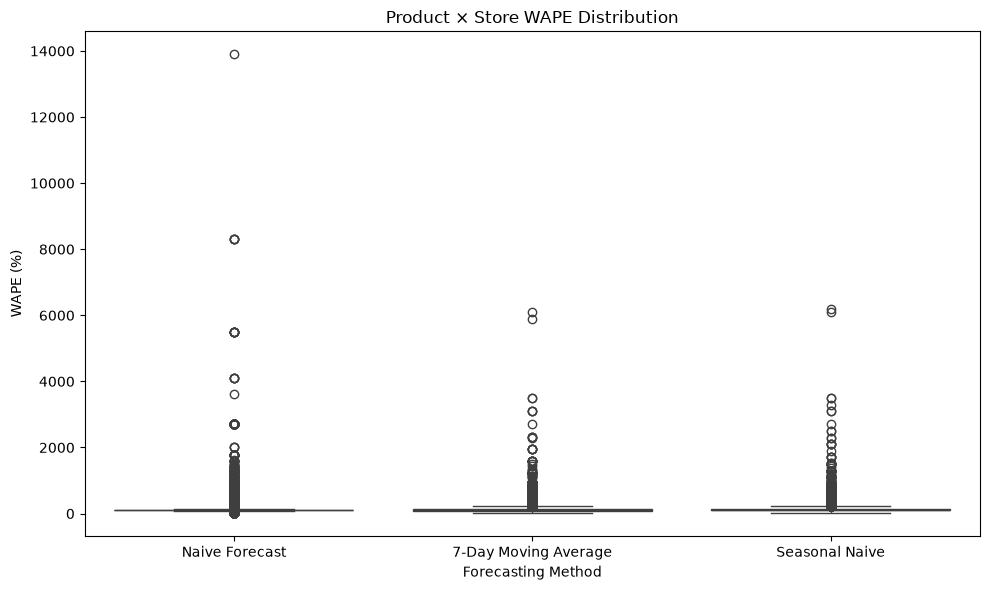

In [93]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=product_store_comparison,
    x="Method",
    y="WAPE"
)

plt.title("Product × Store WAPE Distribution")
plt.xlabel("Forecasting Method")
plt.ylabel("WAPE (%)")
plt.xticks()
plt.tight_layout()
plt.show()

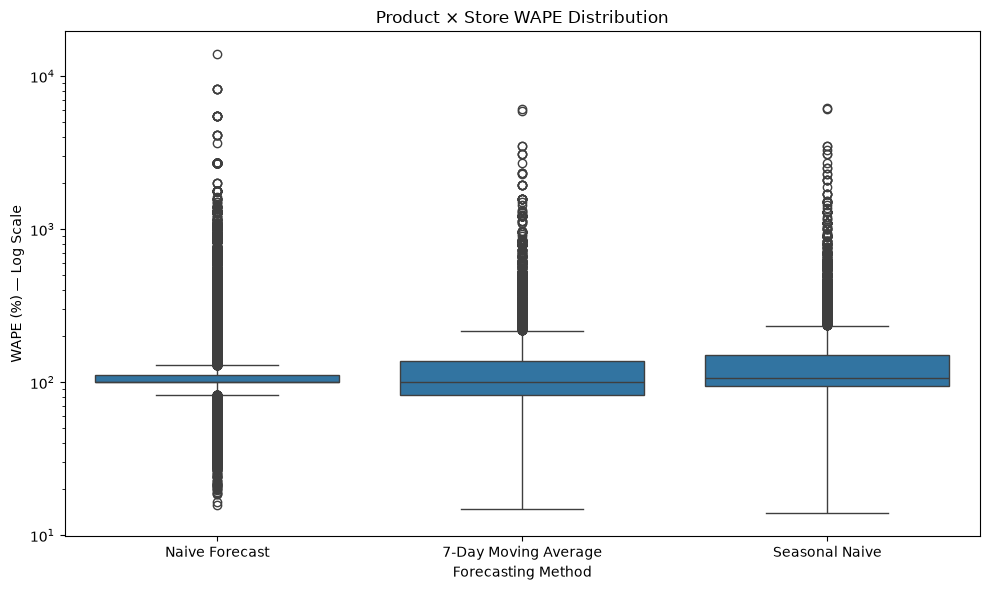

In [95]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=product_store_comparison,
    x="Method",
    y="WAPE"
)

plt.yscale("log")

plt.title("Product × Store WAPE Distribution")
plt.xlabel("Forecasting Method")
plt.ylabel("WAPE (%) — Log Scale")
plt.xticks()
plt.tight_layout()
plt.show()

##### Product × Store Forecast Performance — Key Observations

- Product × Store forecast performance varies substantially across individual demand series.
- The WAPE distributions are strongly right-skewed, with a relatively large number of high-error observations. 
- The 7-Day Moving Average shows a lower central WAPE distribution than the Naive and Seasonal Naive methods during the evaluation period.
- The extreme WAPE values were retained because percentage-based error can become very large for low-volume and intermittent demand series.

## 15. Forecast Visualizations

Forecast metrics summarize forecast performance numerically, but visualizing actual demand against forecast demand helps show how the forecasting methods behave over the evaluation period.

The visualizations will compare actual demand with the forecasts for selected Product × Store demand series.

In [96]:
id_columns = ["item_id", "store_id"]

representative_series = (
    moving_average_evaluation
    .groupby(id_columns)["actual_demand"]
    .sum()
    .sort_values(ascending=False)
    .head(1)
    .reset_index()
)

representative_series

,item_id,store_id,actual_demand
0,FOODS_3_090,CA_3,3357


In [97]:
# prepare the actual and three forecasts

selected_item = representative_series.loc[0, "item_id"]
selected_store = representative_series.loc[0, "store_id"]

forecast_visualization = (
    naive_evaluation[
        (naive_evaluation["item_id"] == selected_item) &
        (naive_evaluation["store_id"] == selected_store)
    ][
        ["d", "day_num", "actual_demand", "forecast_naive"]
    ]
    .merge(
        moving_average_evaluation[
            (moving_average_evaluation["item_id"] == selected_item) &
            (moving_average_evaluation["store_id"] == selected_store)
        ][
            ["d", "forecast_moving_average"]
        ],
        on="d",
        how="left"
    )
    .merge(
        seasonal_naive_evaluation[
            (seasonal_naive_evaluation["item_id"] == selected_item) &
            (seasonal_naive_evaluation["store_id"] == selected_store)
        ][
            ["d", "forecast_seasonal_naive"]
        ],
        on="d",
        how="left"
    )
)

forecast_visualization

,d,day_num,actual_demand,forecast_naive,forecast_moving_average,forecast_seasonal_naive
0,d_1914,1914,133,130,108.714286,86
1,d_1915,1915,117,130,108.714286,100
2,d_1916,1916,113,130,108.714286,88
3,d_1917,1917,99,130,108.714286,77
4,d_1918,1918,196,130,108.714286,141
5,d_1919,1919,132,130,108.714286,139
6,d_1920,1920,114,130,108.714286,130
7,d_1921,1921,114,130,108.714286,86
8,d_1922,1922,93,130,108.714286,100
9,d_1923,1923,77,130,108.714286,88


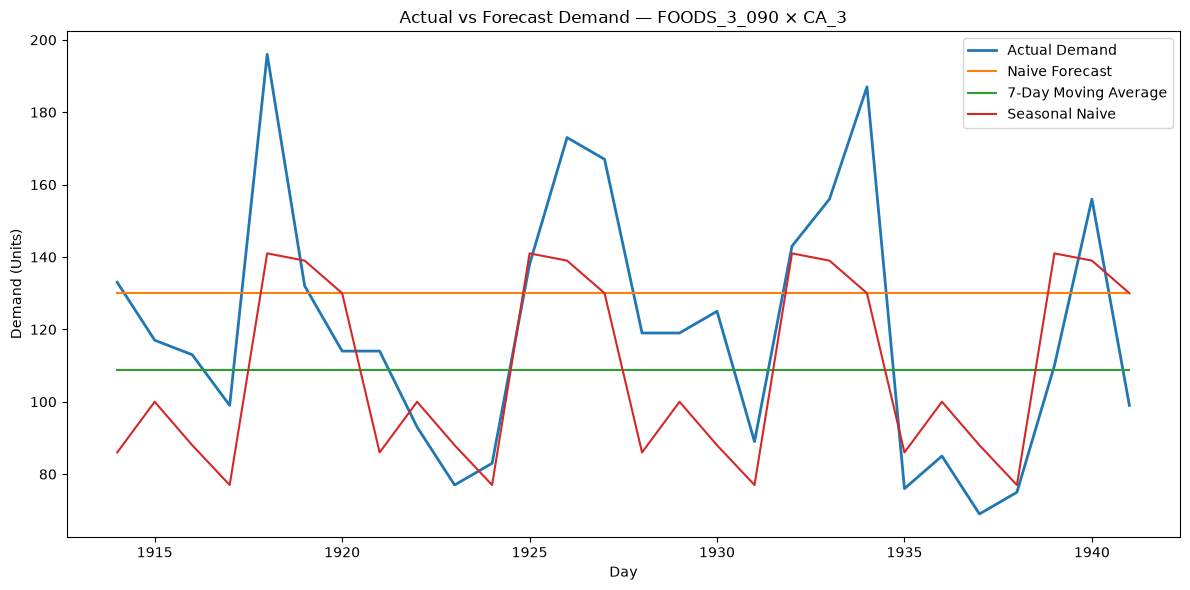

In [98]:
# create the actual vs forecast chart

plt.figure(figsize=(12, 6))

plt.plot(
    forecast_visualization["day_num"],
    forecast_visualization["actual_demand"],
    label="Actual Demand",
    linewidth=2
)

plt.plot(
    forecast_visualization["day_num"],
    forecast_visualization["forecast_naive"],
    label="Naive Forecast"
)

plt.plot(
    forecast_visualization["day_num"],
    forecast_visualization["forecast_moving_average"],
    label="7-Day Moving Average"
)

plt.plot(
    forecast_visualization["day_num"],
    forecast_visualization["forecast_seasonal_naive"],
    label="Seasonal Naive"
)

plt.title("Actual vs Forecast Demand — FOODS_3_090 × CA_3")
plt.xlabel("Day")
plt.ylabel("Demand (Units)")
plt.legend()
plt.tight_layout()
plt.show()

In [99]:
# aggregate daily actual demand vs aggregate forecast demand across all Product × Store combinations

overall_forecast_visualization = (
    naive_evaluation
    .groupby(["d", "day_num"], as_index=False)
    .agg(
        actual_demand=("actual_demand", "sum"),
        naive_forecast=("forecast_naive", "sum")
    )
    .merge(
        moving_average_evaluation
        .groupby(["d", "day_num"], as_index=False)
        .agg(
            moving_average_forecast=(
                "forecast_moving_average",
                "sum"
            )
        ),
        on=["d", "day_num"],
        how="left"
    )
    .merge(
        seasonal_naive_evaluation
        .groupby(["d", "day_num"], as_index=False)
        .agg(
            seasonal_naive_forecast=(
                "forecast_seasonal_naive",
                "sum"
            )
        ),
        on=["d", "day_num"],
        how="left"
    )
)

overall_forecast_visualization

,d,day_num,actual_demand,naive_forecast,moving_average_forecast,seasonal_naive_forecast
0,d_1914,1914,38793,49795,40754.142857,38059
1,d_1915,1915,35487,49795,40754.142857,37570
2,d_1916,1916,34445,49795,40754.142857,35343
3,d_1917,1917,34732,49795,40754.142857,35033
4,d_1918,1918,42896,49795,40754.142857,40517
5,d_1919,1919,50429,49795,40754.142857,48962
6,d_1920,1920,53032,49795,40754.142857,49795
7,d_1921,1921,43181,49795,40754.142857,38059
8,d_1922,1922,44314,49795,40754.142857,37570
9,d_1923,1923,39601,49795,40754.142857,35343


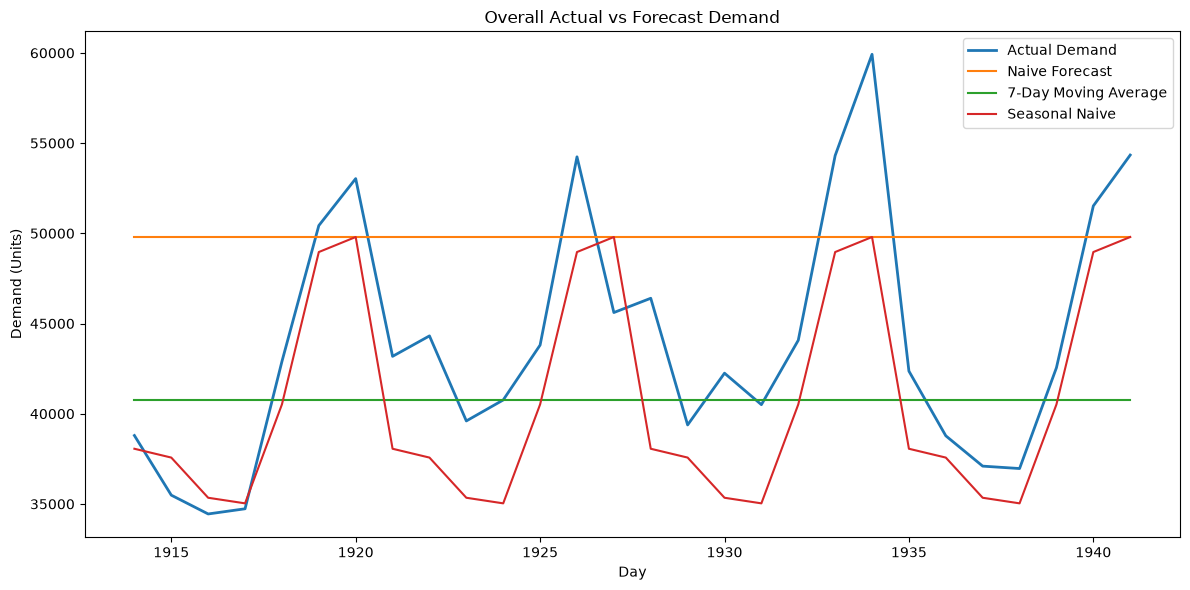

In [100]:
# plot overall actual vs forecast

plt.figure(figsize=(12, 6))

plt.plot(
    overall_forecast_visualization["day_num"],
    overall_forecast_visualization["actual_demand"],
    label="Actual Demand",
    linewidth=2
)

plt.plot(
    overall_forecast_visualization["day_num"],
    overall_forecast_visualization["naive_forecast"],
    label="Naive Forecast"
)

plt.plot(
    overall_forecast_visualization["day_num"],
    overall_forecast_visualization["moving_average_forecast"],
    label="7-Day Moving Average"
)

plt.plot(
    overall_forecast_visualization["day_num"],
    overall_forecast_visualization["seasonal_naive_forecast"],
    label="Seasonal Naive"
)

plt.title("Overall Actual vs Forecast Demand")
plt.xlabel("Day")
plt.ylabel("Demand (Units)")
plt.legend()
plt.tight_layout()
plt.show()

## 16. Forecasting Conclusion

- The three practical forecasting methods were evaluated over a 28-day holdout period from **April 25, 2016 to May 22, 2016** at the **Product × Store** level.

- The 7-Day Moving Average produced the lowest overall WAPE and MAE among the three methods during this evaluation period. The Seasonal Naive method incorporated the observed weekly demand pattern but produced higher error than the 7-Day Moving Average, while the Naive Forecast produced the highest overall WAPE and MAE.

- Forecast performance varied substantially across categories, stores, and individual Product × Store demand series. The Product × Store analysis also showed a highly dispersed and right-skewed WAPE distribution, particularly for low-volume and intermittent demand series.

- These results provide a practical baseline for evaluating retail demand forecasts. The forecast errors will be analyzed further in the next notebook to identify where errors are highest and what demand patterns are associated with them.

- These results provide a practical baseline for evaluating retail demand forecasts. Among the methods tested, the 7-Day Moving Average produced the lowest observed overall WAPE and MAE for this evaluation period. However, forecast performance varied substantially across individual demand series, so overall accuracy alone does not explain where forecasting is difficult. The next analysis will investigate the distribution and drivers of forecast error.

## 17. Export Forecast Results

In [101]:
forecast_results = (
    naive_evaluation[
        [
            "item_id",
            "store_id",
            "d",
            "day_num",
            "actual_demand",
            "forecast_naive"
        ]
    ]
    .merge(
        moving_average_evaluation[
            [
                "item_id",
                "store_id",
                "d",
                "forecast_moving_average"
            ]
        ],
        on=["item_id", "store_id", "d"],
        how="left"
    )
    .merge(
        seasonal_naive_evaluation[
            [
                "item_id",
                "store_id",
                "d",
                "forecast_seasonal_naive"
            ]
        ],
        on=["item_id", "store_id", "d"],
        how="left"
    )
)

forecast_results.shape

(853720, 8)

In [102]:
forecast_results.head()

,item_id,store_id,d,day_num,actual_demand,forecast_naive,forecast_moving_average,forecast_seasonal_naive
0,FOODS_1_001,CA_1,d_1914,1914,2,0,1.142857,4
1,FOODS_1_001,CA_1,d_1915,1915,0,0,1.142857,1
2,FOODS_1_001,CA_1,d_1916,1916,0,0,1.142857,1
3,FOODS_1_001,CA_1,d_1917,1917,0,0,1.142857,0
4,FOODS_1_001,CA_1,d_1918,1918,0,0,1.142857,1


In [103]:
forecast_results.isna().sum()

item_id                    0
store_id                   0
d                          0
day_num                    0
actual_demand              0
forecast_naive             0
forecast_moving_average    0
forecast_seasonal_naive    0
dtype: int64

In [104]:
forecast_results.to_csv(
    "../data/processed/analytical/forecast_results.csv",
    index=False
)